# Spam SMS Detection — Exploratory Data Analysis & Modelling

CodSoft ML Internship · Task 4

This notebook walks through the actual `data/spam.csv` dataset: inspection, cleaning, EDA and a model comparison. The production pipeline lives in `train.py` / `src/`; this notebook reuses the same code.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from src.data_preprocessing import load_raw_data, clean_dataset
from src import eda

## 1. Inspect the raw dataset

In [2]:
raw = load_raw_data()
print(raw.shape)
raw.head()

(5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
raw.info()
raw.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 677.1 KB


v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

The `Unnamed: 2..4` columns are mostly empty. Where they are filled, they hold the **rest of a message** that contained commas (a CSV quoting artefact):

In [4]:
raw[raw['Unnamed: 2'].notna()].head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
95,spam,Your free ringtone is waiting to be collected....,PO Box 5249,"MK17 92H. 450Ppw 16""",NaN
281,ham,\Wen u miss someone,the person is definitely special for u..... B...,why to miss them,"just Keep-in-touch\"" gdeve.."""
444,ham,\HEY HEY WERETHE MONKEESPEOPLE SAY WE MONKEYAR...,HOWU DOIN? FOUNDURSELF A JOBYET SAUSAGE?LOVE ...,NaN,NaN
671,spam,SMS. ac sun0819 posts HELLO:\You seem cool,"wanted to say hi. HI!!!\"" Stop? Send STOP to ...",NaN,NaN
710,ham,Height of Confidence: All the Aeronautics prof...,"this wont even start........ Datz confidence..""",NaN,NaN


In [5]:
print('Exact duplicate rows:', raw.duplicated(subset=['v1', 'v2']).sum())
raw['v1'].value_counts()

Exact duplicate rows: 403


v1
ham     4825
spam     747
Name: count, dtype: int64

## 2. Clean the data
Overflow text is merged back into the message, the unnamed columns are dropped, missing rows and duplicates are removed, and labels are encoded `ham → 0`, `spam → 1`.

In [6]:
df, summary = clean_dataset(raw)
summary

{'raw_rows': 5572,
 'raw_columns': ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'],
 'rows_with_overflow_text': 50,
 'dropped_columns': ['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'],
 'missing_rows_removed': 0,
 'invalid_label_rows_removed': 0,
 'duplicate_rows_removed': 414,
 'clean_rows': 5158,
 'class_counts': {'ham': 4516, 'spam': 642}}

In [7]:
df.head()

,label,message,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 3. Class distribution

label
ham     4516
spam     642
Name: count, dtype: int64
label
ham     87.55
spam    12.45
Name: count, dtype: float64


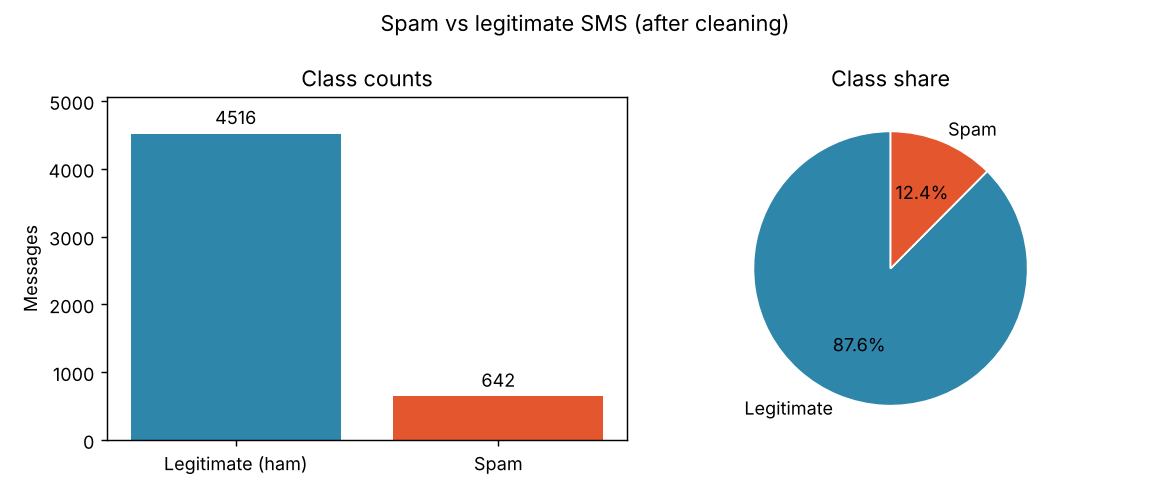

In [8]:
counts = df['label'].value_counts()
print(counts)
print((counts / counts.sum() * 100).round(2))
eda.plot_class_distribution(df, Path('reports/figures/class_distribution.png'))
from IPython.display import Image
Image('reports/figures/class_distribution.png')

The data is **imbalanced** (~87.6% legitimate / ~12.4% spam), so accuracy on its own is misleading. The models are compared on spam precision, recall and F1, and the split is stratified.

## 4. Message characteristics

In [9]:
eda.length_summary(df)

,char_count,word_count,digit_count,upper_ratio
label,,,,
ham,71.02,14.24,0.30,0.08
spam,137.88,23.70,15.44,0.16


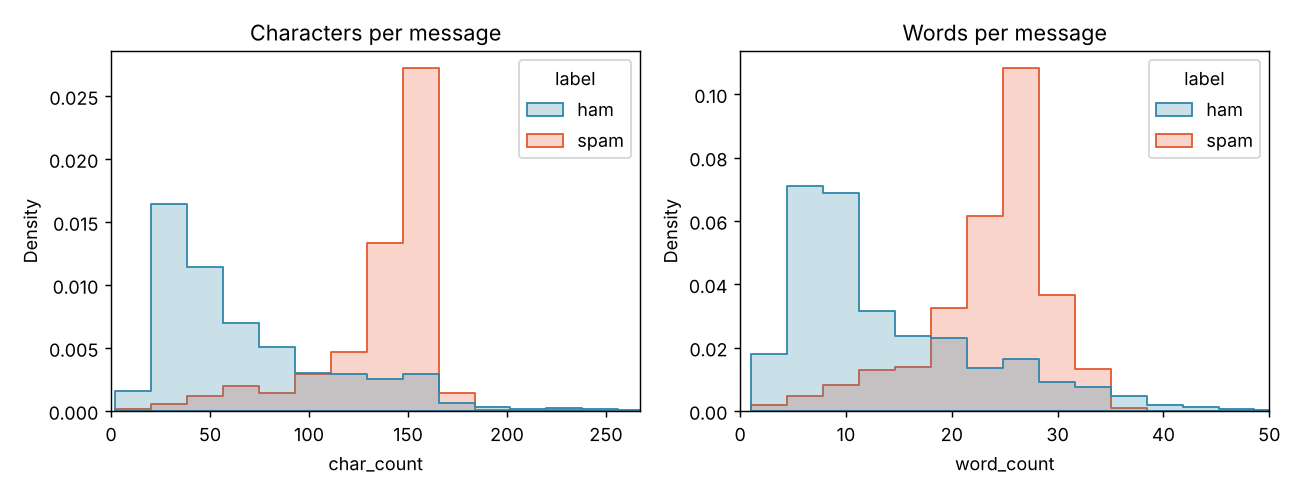

In [10]:
eda.plot_length_distribution(df, Path('reports/figures/message_length_distribution.png'))
Image('reports/figures/message_length_distribution.png')

Spam messages are about twice as long, and contain far more digits (phone numbers, short codes, prize amounts) and upper-case letters.

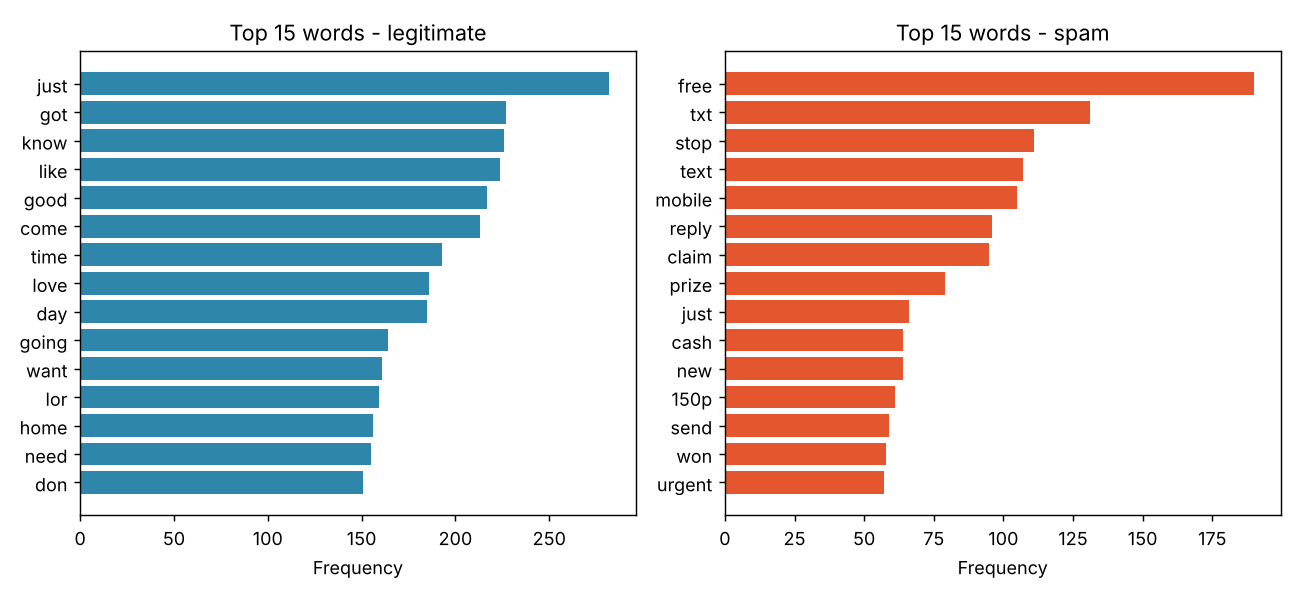

In [11]:
eda.plot_top_words(df, Path('reports/figures/top_words.png'))
Image('reports/figures/top_words.png')

## 5. Model comparison
The models are trained by `train.py`, which uses stratified 80/20 splitting, TF-IDF inside a `Pipeline` (no leakage), and 5-fold CV grid search on the training set. The saved results are loaded here:

In [12]:
comparison = pd.read_csv('reports/model_comparison.csv', index_col='model')
comparison[['accuracy','precision_spam','recall_spam','f1_spam','roc_auc','cv_f1','fn','fp']]

,accuracy,precision_spam,recall_spam,f1_spam,roc_auc,cv_f1,fn,fp
model,,,,,,,,
Multinomial Naive Bayes,0.9864,0.9831,0.9062,0.9431,0.9917,0.9515,12,2
Logistic Regression,0.9884,0.9394,0.9688,0.9538,0.9988,0.9587,4,8
Support Vector Machine,0.9884,0.9328,0.9766,0.9542,0.9985,0.9570,3,9


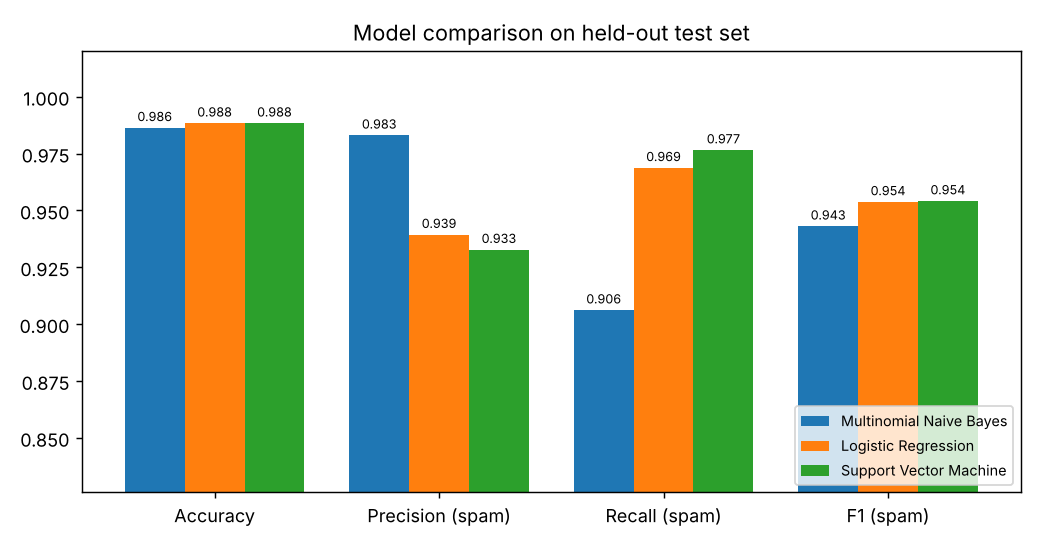

In [13]:
Image('reports/figures/model_comparison.png')

Selected model: Logistic Regression | highest mean 5-fold CV spam F1 on training set


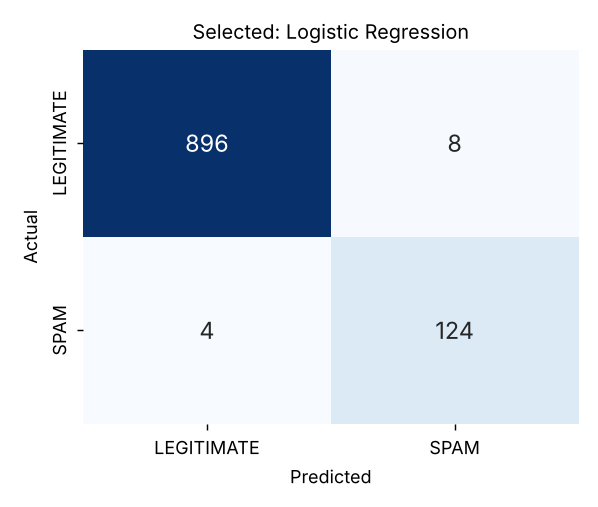

In [14]:
import json
m = json.load(open('reports/metrics.json'))
print('Selected model:', m['best_model'], '|', m['selection_criterion'])
Image('reports/figures/best_model_confusion_matrix.png')

## 6. Using the saved pipeline

In [15]:
from src.predict import load_model, predict_message
model = load_model()
for msg in ['Congratulations! You won a £500 voucher. Call 09061701461 to claim now',
            'Can you send me the notes from today\'s lecture?']:
    print(predict_message(msg, model), '<-', msg)

{'label': 'SPAM', 'is_spam': True, 'confidence': 0.9999999071756427, 'spam_probability': 0.9999999071756427} <- Congratulations! You won a £500 voucher. Call 09061701461 to claim now
{'label': 'LEGITIMATE', 'is_spam': False, 'confidence': 0.9945737193521297, 'spam_probability': 0.005426280647870264} <- Can you send me the notes from today's lecture?
